In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

project_root = Path.cwd().parent
data_path = project_root / "data" / "processed" / "apl_logistics_cleaned.csv"

print("Using file:", data_path)
print("File exists:", data_path.is_file())

df = pd.read_csv(data_path)

print("Regional & Shipping Analysis")
print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Using file: c:\Users\klarikach\OneDrive\Documents\supply chain profitability\data\processed\apl_logistics_cleaned.csv
File exists: True
Regional & Shipping Analysis
Dataset loaded successfully!
Rows: 180519
Columns: 40


In [3]:
from pathlib import Path

project_root = Path.cwd().parent
processed_folder = project_root / "data" / "processed"

print("Processed folder exists:", processed_folder.exists())
print("Files in processed folder:")

if processed_folder.exists():
    for file in processed_folder.iterdir():
        print(file.name)

Processed folder exists: True
Files in processed folder:
apl_logistics_cleaned.csv
apl_logistics_final.csv


In [7]:
region_summary = df.groupby("Order Region").agg(
    Total_Net_Sales=("Order Item Total", "sum"),
    Total_Profit=("Order Profit Per Order", "sum"),
    Total_Discounts=("Order Item Discount", "sum"),
    Transaction_Rows=("Order Item Total", "count")
).reset_index()

region_summary["Profit_Margin_Percent"] = (
    region_summary["Total_Profit"]
    / region_summary["Total_Net_Sales"]
) * 100

display(
    region_summary.sort_values(
        "Total_Profit",
        ascending=False
    ).round(2)
)

,Order Region,Total_Net_Sales,Total_Profit,Total_Discounts,Transaction_Rows,Profit_Margin_Percent
22,Western Europe,5296002.84,625446.08,598384.31,27109,11.81
3,Central America,5093849.66,616341.57,571869.41,28341,12.10
12,South America,2660243.66,335154.40,300641.19,14935,12.60
10,Northern Europe,1939362.41,233450.60,216470.73,9792,12.04
17,Southern Europe,1837525.80,230829.23,210395.35,9431,12.56
15,Southeast Asia,1738553.42,211342.82,193945.36,9539,12.16
11,Oceania,1809996.53,201478.02,206660.62,10148,11.13
1,Caribbean,1481668.67,171825.64,169352.55,8318,11.60
13,South Asia,1397364.56,165703.90,156318.69,7731,11.86
21,West of USA,1412253.58,164940.66,159164.32,7993,11.68


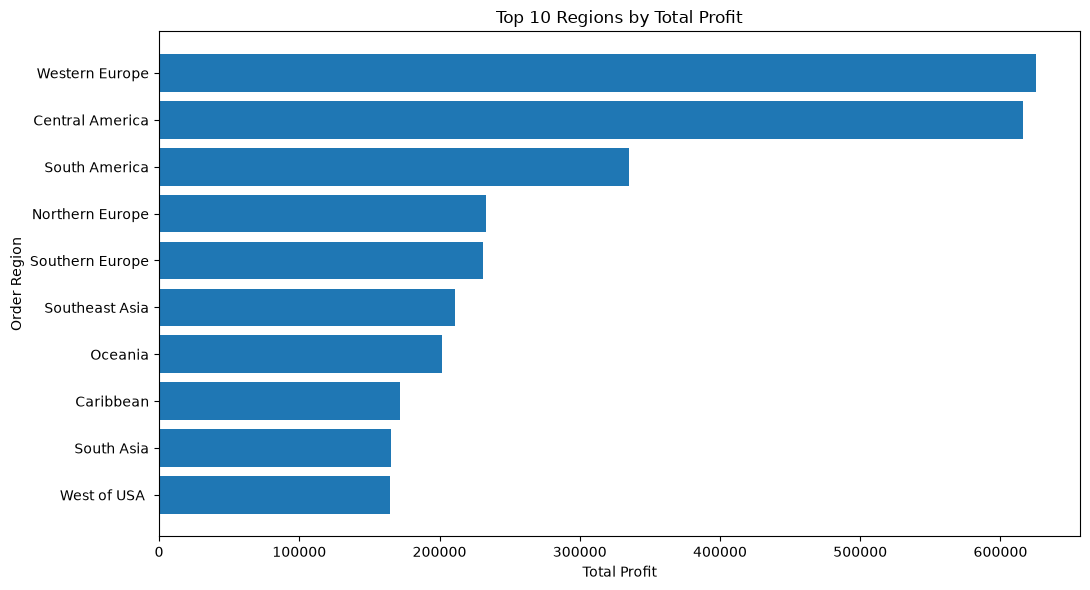

In [8]:
top_regions = region_summary.nlargest(
    10, "Total_Profit"
).sort_values("Total_Profit")

plt.figure(figsize=(11, 6))

plt.barh(
    top_regions["Order Region"],
    top_regions["Total_Profit"]
)

plt.title("Top 10 Regions by Total Profit")
plt.xlabel("Total Profit")
plt.ylabel("Order Region")
plt.ticklabel_format(axis="x", style="plain")
plt.tight_layout()
plt.show()

In [9]:
shipping_summary = df.groupby("Shipping Mode").agg(
    Total_Net_Sales=("Order Item Total", "sum"),
    Total_Profit=("Order Profit Per Order", "sum"),
    Transaction_Rows=("Order Item Total", "count"),
    Avg_Actual_Shipping_Days=("Days for shipping (real)", "mean"),
    Avg_Scheduled_Shipping_Days=("Days for shipment (scheduled)", "mean")
).reset_index()

shipping_summary["Profit_Margin_Percent"] = (
    shipping_summary["Total_Profit"]
    / shipping_summary["Total_Net_Sales"]
) * 100

display(shipping_summary.round(2))

,Shipping Mode,Total_Net_Sales,Total_Profit,Transaction_Rows,Avg_Actual_Shipping_Days,Avg_Scheduled_Shipping_Days,Profit_Margin_Percent
0,First Class,5100451.02,643121.92,27814,2.00,1.0,12.61
1,Same Day,1745201.51,203018.43,9737,0.48,0.0,11.63
2,Second Class,6416528.47,750308.17,35216,3.99,2.0,11.69
3,Standard Class,19792221.04,2370454.45,107752,4.00,4.0,11.98


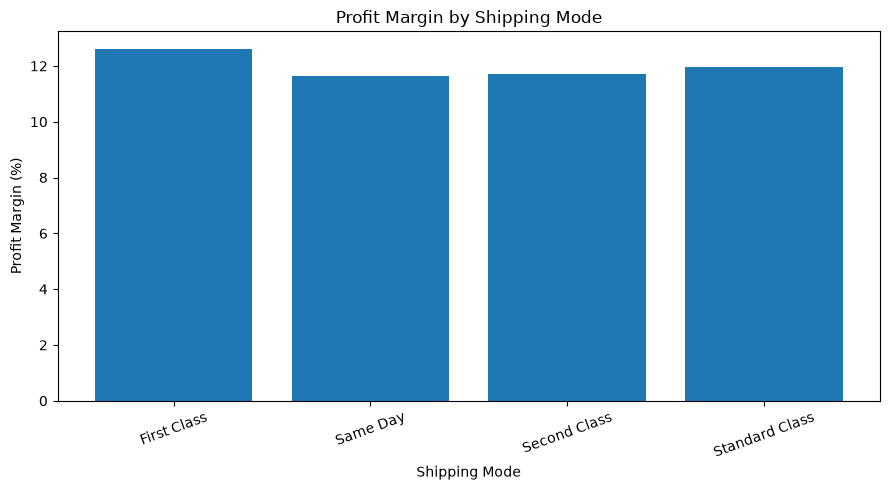

In [10]:
plt.figure(figsize=(9, 5))

plt.bar(
    shipping_summary["Shipping Mode"],
    shipping_summary["Profit_Margin_Percent"]
)

plt.title("Profit Margin by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [11]:
delivery_summary = df.groupby("Delivery Status").agg(
    Transaction_Rows=("Delivery Status", "size"),
    Total_Net_Sales=("Order Item Total", "sum"),
    Total_Profit=("Order Profit Per Order", "sum"),
    Avg_Actual_Shipping_Days=("Days for shipping (real)", "mean"),
    Avg_Scheduled_Shipping_Days=("Days for shipment (scheduled)", "mean")
).reset_index()

display(delivery_summary.round(2))

,Delivery Status,Transaction_Rows,Total_Net_Sales,Total_Profit,Avg_Actual_Shipping_Days,Avg_Scheduled_Shipping_Days
0,Advance shipping,41592,7656338.67,935225.28,2.50,4.00
1,Late delivery,98977,18082555.11,2140051.68,4.09,2.47
2,Shipping canceled,7754,1409737.29,160482.34,3.48,2.90
3,Shipping on time,32196,5905770.97,731143.67,2.98,2.98


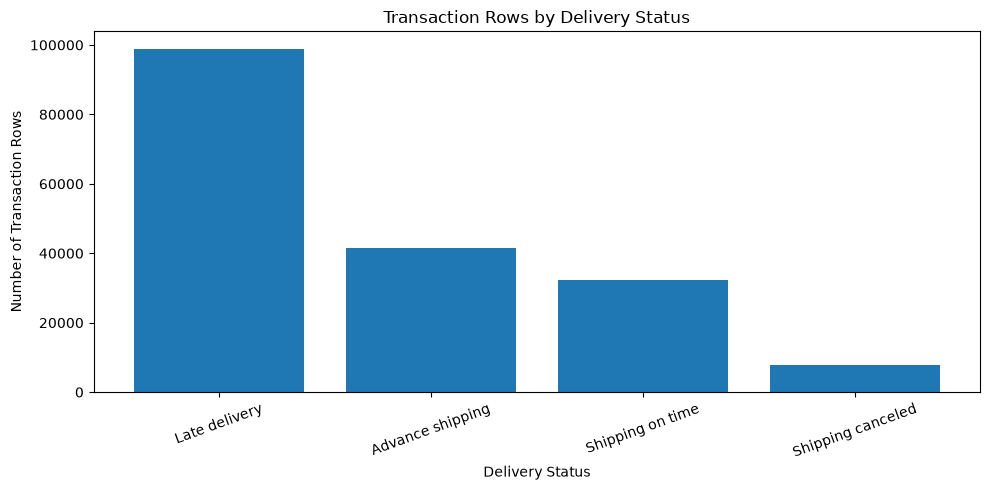

In [12]:
delivery_counts = delivery_summary.sort_values(
    "Transaction_Rows",
    ascending=False
)

plt.figure(figsize=(10, 5))

plt.bar(
    delivery_counts["Delivery Status"],
    delivery_counts["Transaction_Rows"]
)

plt.title("Transaction Rows by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Transaction Rows")
plt.xticks(rotation=20)
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()

In [13]:
best_region = region_summary.loc[
    region_summary["Profit_Margin_Percent"].idxmax()
]

lowest_region = region_summary.loc[
    region_summary["Profit_Margin_Percent"].idxmin()
]

best_shipping = shipping_summary.loc[
    shipping_summary["Total_Profit"].idxmax()
]

most_common_delivery = delivery_summary.loc[
    delivery_summary["Transaction_Rows"].idxmax()
]

print("REGIONAL & SHIPPING BUSINESS INSIGHTS")
print("-" * 45)

print(
    f"Highest regional profit margin: "
    f"{best_region['Order Region']} "
    f"({best_region['Profit_Margin_Percent']:.2f}%)"
)

print(
    f"Lowest regional profit margin: "
    f"{lowest_region['Order Region']} "
    f"({lowest_region['Profit_Margin_Percent']:.2f}%)"
)

print(
    f"Shipping mode generating the highest total profit: "
    f"{best_shipping['Shipping Mode']} "
    f"(${best_shipping['Total_Profit']:,.2f})"
)

print(
    f"Most common delivery status: "
    f"{most_common_delivery['Delivery Status']} "
    f"({most_common_delivery['Transaction_Rows']:,} rows)"
)


REGIONAL & SHIPPING BUSINESS INSIGHTS
---------------------------------------------
Highest regional profit margin: Southern Africa (15.09%)
Lowest regional profit margin: Eastern Asia (11.04%)
Shipping mode generating the highest total profit: Standard Class ($2,370,454.45)
Most common delivery status: Late delivery (98,977 rows)


Profitability by Market


,Market,Total_Net_Sales,Total_Profit,Total_Discounts,Profit_Margin_Percent
1,Europe,9769198.23,1169442.96,1103210.75,11.97
2,LATAM,9235761.99,1123321.61,1041863.15,12.16
3,Pacific Asia,7434262.58,857753.44,839493.31,11.54
4,USCA,4553499.87,564313.78,513034.82,12.39
0,Africa,2061679.37,252071.18,232776.37,12.23


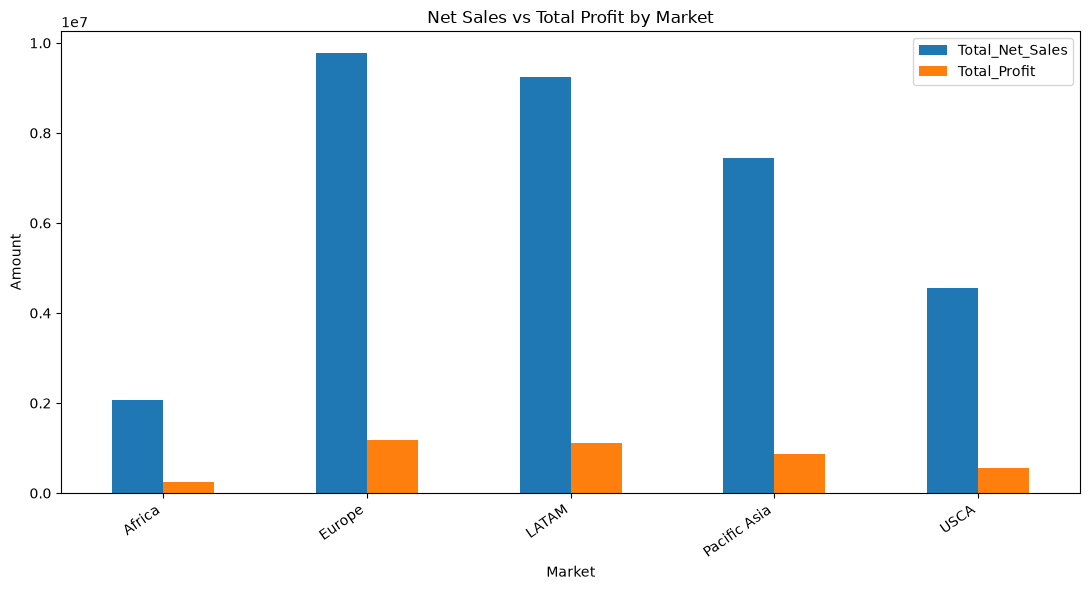

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

data_path = (
    Path.cwd().parent
    / "data"
    / "processed"
    / "apl_logistics_cleaned.csv"
)

df = pd.read_csv(data_path)

market_summary = df.groupby("Market", as_index=False).agg(
    Total_Net_Sales=("Order Item Total", "sum"),
    Total_Profit=("Order Profit Per Order", "sum"),
    Total_Discounts=("Order Item Discount", "sum")
)

market_summary["Profit_Margin_Percent"] = (
    market_summary["Total_Profit"]
    / market_summary["Total_Net_Sales"].replace(0, float("nan"))
) * 100

print("Profitability by Market")
display(
    market_summary.sort_values(
        "Total_Profit", ascending=False
    ).round(2)
)

market_summary.set_index("Market")[
    ["Total_Net_Sales", "Total_Profit"]
].plot(
    kind="bar",
    figsize=(11, 6),
    title="Net Sales vs Total Profit by Market"
)

plt.xlabel("Market")
plt.ylabel("Amount")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


Top 10 Countries by Total Profit


,Order Country,Total_Net_Sales,Total_Profit,Total_Discounts,Profit_Margin_Percent
48,Estados Unidos,4385242.45,540413.07,494431.00,12.32
53,Francia,2590323.47,327828.58,289622.01,12.66
102,México,2368426.06,303278.37,264772.55,12.81
2,Alemania,1862577.57,194827.08,211596.41,10.46
20,Brasil,1433100.98,186713.64,161220.72,13.03
120,Reino Unido,1450047.22,180942.88,162049.44,12.48
8,Australia,1521410.40,170041.58,173213.78,11.18
31,China,1052752.57,122190.92,120151.34,11.61
75,Italia,963830.33,121545.47,108352.51,12.61
69,India,865968.88,99746.82,96429.20,11.52


Bottom 10 Countries by Total Profit


,Order Country,Total_Net_Sales,Total_Profit,Total_Discounts,Profit_Margin_Percent
63,Guinea-Bissau,4591.24,-1448.72,578.17,-31.55
146,Taiwán,5821.11,-1374.54,575.22,-23.61
127,Ruanda,17101.56,-330.02,1811.48,-1.93
18,Bosnia y Herzegovina,7804.97,-327.38,1064.16,-4.19
98,Mongolia,14059.50,-286.23,1422.26,-2.04
29,Chad,524.96,-272.71,75.00,-51.95
125,República de Gambia,1244.37,-265.83,205.49,-21.36
60,Guayana Francesa,1577.86,-231.88,126.89,-14.70
14,Belice,2328.16,-228.35,166.65,-9.81
144,Sáhara Occidental,585.96,-17.52,14.00,-2.99


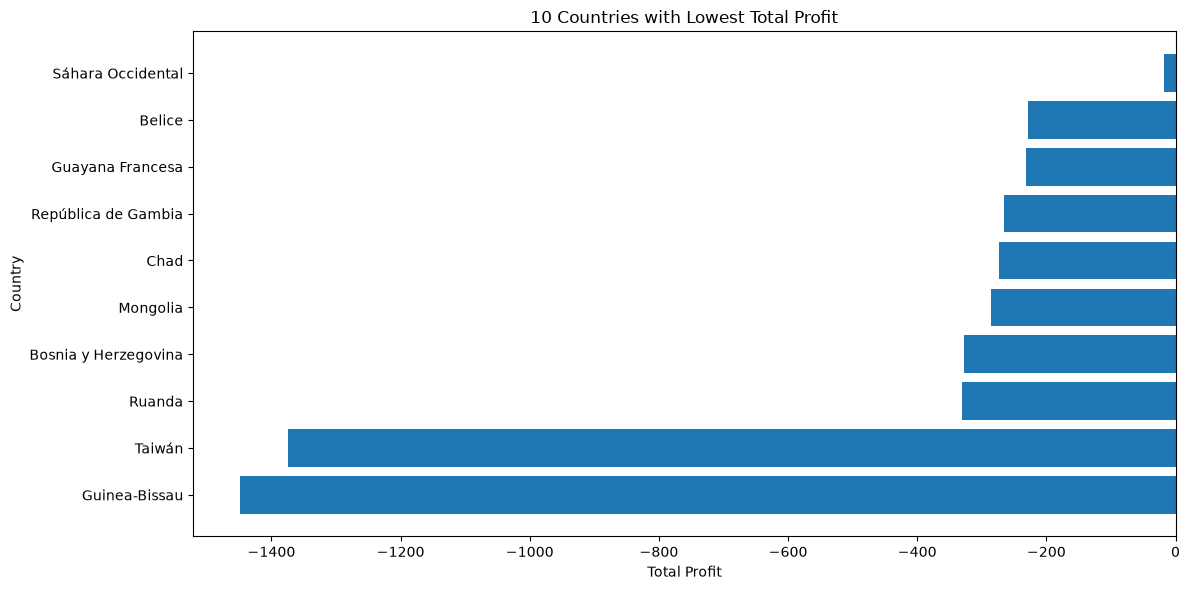

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load cleaned dataset
data_path = (
    Path.cwd().parent
    / "data"
    / "processed"
    / "apl_logistics_cleaned.csv"
)
df = pd.read_csv(data_path)

# Country-level profitability
country_summary = df.groupby("Order Country", as_index=False).agg(
    Total_Net_Sales=("Order Item Total", "sum"),
    Total_Profit=("Order Profit Per Order", "sum"),
    Total_Discounts=("Order Item Discount", "sum")
)

country_summary["Profit_Margin_Percent"] = (
    country_summary["Total_Profit"]
    / country_summary["Total_Net_Sales"].replace(0, float("nan"))
) * 100

print("Top 10 Countries by Total Profit")
display(
    country_summary.nlargest(10, "Total_Profit").round(2)
)

print("Bottom 10 Countries by Total Profit")
display(
    country_summary.nsmallest(10, "Total_Profit").round(2)
)

bottom_countries = country_summary.nsmallest(
    10, "Total_Profit"
).sort_values("Total_Profit")

plt.figure(figsize=(12, 6))
plt.barh(
    bottom_countries["Order Country"],
    bottom_countries["Total_Profit"]
)
plt.title("10 Countries with Lowest Total Profit")
plt.xlabel("Total Profit")
plt.ylabel("Country")
plt.tight_layout()
plt.show()
